# Monte Carlo Option Pricing and Portfolio VaR



## 1. Upload the script


In [9]:

!rm -f monte_carlo_risk*.py
from google.colab import files
up = files.upload()
print(list(up))
!grep -c "load_yf_csv" monte_carlo_risk.py

Saving monte_carlo_risk (1).py to monte_carlo_risk (1).py
['monte_carlo_risk (1).py']
grep: monte_carlo_risk.py: No such file or directory


## 2. Get the Kaggle CSV into Colab



In [10]:

up = files.upload()
CSV = list(up)[0]
print("Using:", CSV)

Saving SnP_daily_update.csv to SnP_daily_update (1).csv
Using: SnP_daily_update (1).csv


## 3. Inspect the data before trusting it


In [11]:
import pandas as pd
top = pd.read_csv(CSV, header=None, nrows=3, low_memory=False)
if str(top.iloc[0, 0]).lower() == "price" and str(top.iloc[1, 0]).lower() == "ticker":
    print("Format: yfinance-style wide file (one block of columns per field).")
    fields = top.iloc[0, 1:].astype(str).str.replace(r"\.\d+$", "", regex=True)
    tickers = top.iloc[1, 1:].astype(str).unique()
    dates = pd.read_csv(CSV, header=None, skiprows=3, usecols=[0])[0]
    print("Fields:", fields.unique().tolist())
    print("Number of tickers:", len(tickers))
    print("Rows:", len(dates), "| Date range:", dates.min(), "to", dates.max())
    check = ["AAPL", "MSFT", "JPM", "XOM", "JNJ"]
    print("Not in file:", [t for t in check if t not in tickers])
else:
    head = pd.read_csv(CSV, nrows=5)
    display(head)
    print(head.columns.tolist())

Format: yfinance-style wide file (one block of columns per field).
Fields: ['Close', 'High', 'Low', 'Open', 'Volume']
Number of tickers: 503
Rows: 4248 | Date range: 2010-01-04 to 2026-11-20
Not in file: []


## 4. Run the project


In [13]:
import glob, os, shutil
from google.colab import files
files.upload()
latest = sorted(glob.glob("monte_carlo_risk*.py"), key=os.path.getmtime)[-1]
if latest != "monte_carlo_risk.py":
    shutil.copy(latest, "monte_carlo_risk.py")
!grep -c "load_yf_csv" monte_carlo_risk.py

Saving monte_carlo_risk (1).py to monte_carlo_risk (1) (2).py
2


In [14]:
TICKERS = "AAPL MSFT JPM XOM JNJ"
START, END = "2010-01-01", "2026-11-01"
!python monte_carlo_risk.py --source csv --csv "$CSV" --tickers $TICKERS --start $START --end $END

monte_carlo_risk v3 (handles Kaggle long files and yfinance-style multi-header files)

=== PART 1: European call, Monte Carlo vs Black-Scholes ===
Inputs: S0=100, K=100, T=1.0, r=0.05, sigma=0.2
Black-Scholes price: 10.4506
 black_scholes   paths  antithetic  mc_price  std_error  abs_error  ci95_low  ci95_high
       10.4506     100       False    7.8258     1.0120     2.6248    5.8423     9.8092
       10.4506     100        True   10.3315     1.0721     0.1191    8.2302    12.4329
       10.4506    1000       False   10.1477     0.4541     0.3029    9.2576    11.0377
       10.4506    1000        True   11.0026     0.3506     0.5520   10.3154    11.6897
       10.4506   10000       False   10.3949     0.1487     0.0557   10.1034    10.6864
       10.4506   10000        True   10.3747     0.1031     0.0759   10.1725    10.5768
       10.4506  100000       False   10.4414     0.0469     0.0092   10.3496    10.5333
       10.4506  100000        True   10.4818     0.0330     0.0313   10.

## 5. Look at the outputs

option_convergence.csv


,black_scholes,paths,antithetic,mc_price,std_error,abs_error,ci95_low,ci95_high
0,10.4506,100,False,7.8258,1.0120,2.6248,5.8423,9.8092
1,10.4506,100,True,10.3315,1.0721,0.1191,8.2302,12.4329
2,10.4506,1000,False,10.1477,0.4541,0.3029,9.2576,11.0377
3,10.4506,1000,True,11.0026,0.3506,0.5520,10.3154,11.6897
4,10.4506,10000,False,10.3949,0.1487,0.0557,10.1034,10.6864
5,10.4506,10000,True,10.3747,0.1031,0.0759,10.1725,10.5768
6,10.4506,100000,False,10.4414,0.0469,0.0092,10.3496,10.5333
7,10.4506,100000,True,10.4818,0.0330,0.0313,10.4172,10.5465
8,10.4506,1000000,False,10.4524,0.0147,0.0018,10.4236,10.4812
9,10.4506,1000000,True,10.4570,0.0104,0.0065,10.4367,10.4774


var_es_results.csv


,confidence,method,VaR_pct,ES_pct,VaR_money,ES_money
0,0.95,Historical,1.6333,2.6086,16332.9548,26085.8719
1,0.95,Parametric (normal),1.7588,2.2245,17587.8579,22245.2547
2,0.95,Monte Carlo,1.7558,2.2199,17558.4419,22198.5770
3,0.99,Historical,3.1879,4.3909,31879.3745,43908.6578
4,0.99,Parametric (normal),2.5184,2.8961,25183.6923,28960.6467
5,0.99,Monte Carlo,2.5173,2.8838,25172.8694,28838.1949


backtest_results.csv


,model,observations,exceptions,expected,kupiec_LR,p_value,verdict
0,hist_VaR,3982,53,39.8,3.9919,0.0457,reject
1,param_VaR,3982,89,39.8,45.4156,0.0000,reject


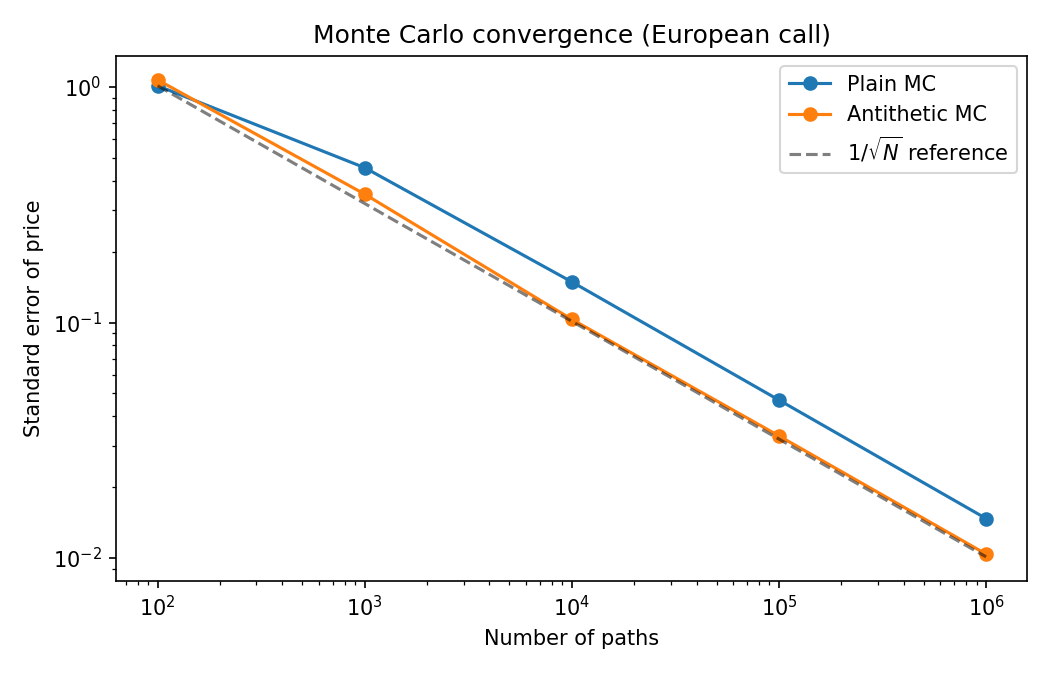

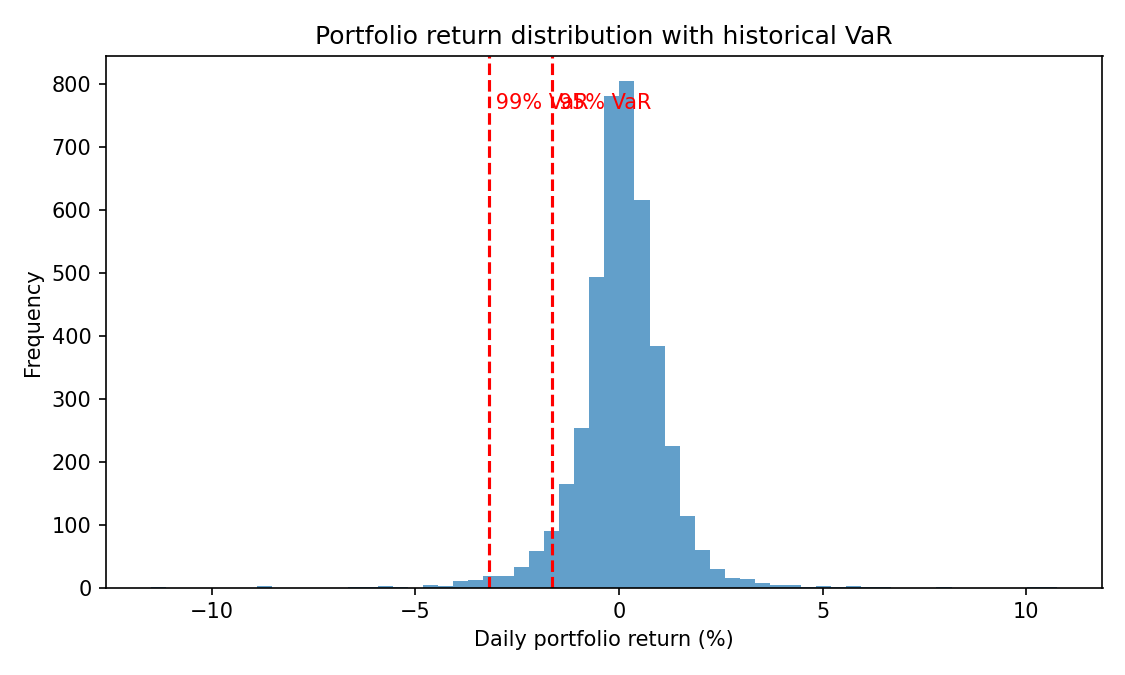

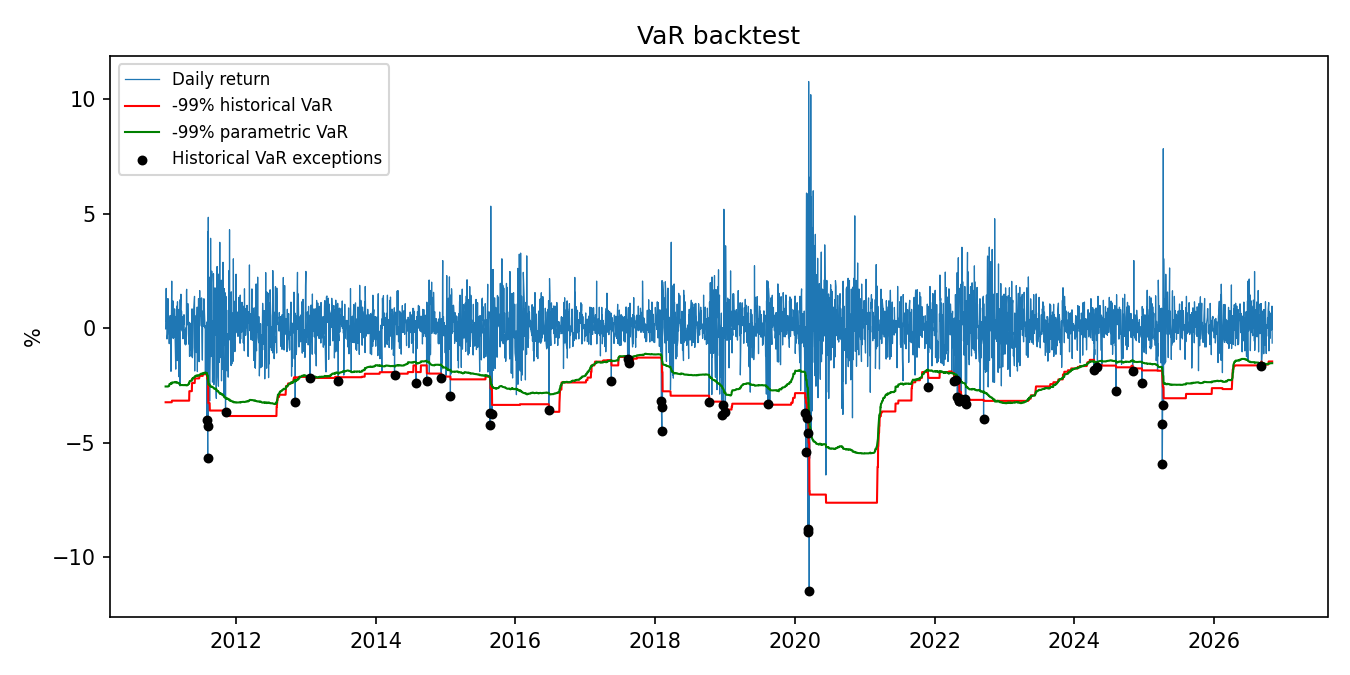

In [15]:
import pandas as pd
from IPython.display import Image, display
for f in ["option_convergence.csv","var_es_results.csv","backtest_results.csv"]:
    print(f); display(pd.read_csv("results/"+f).round(4))
for img in ["option_convergence.png","return_distribution.png","var_backtest.png"]:
    display(Image("results/"+img))

## 6. Save your work


In [16]:
!zip -rq results.zip results
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>